##  House Price Prediction Using Machine Learning

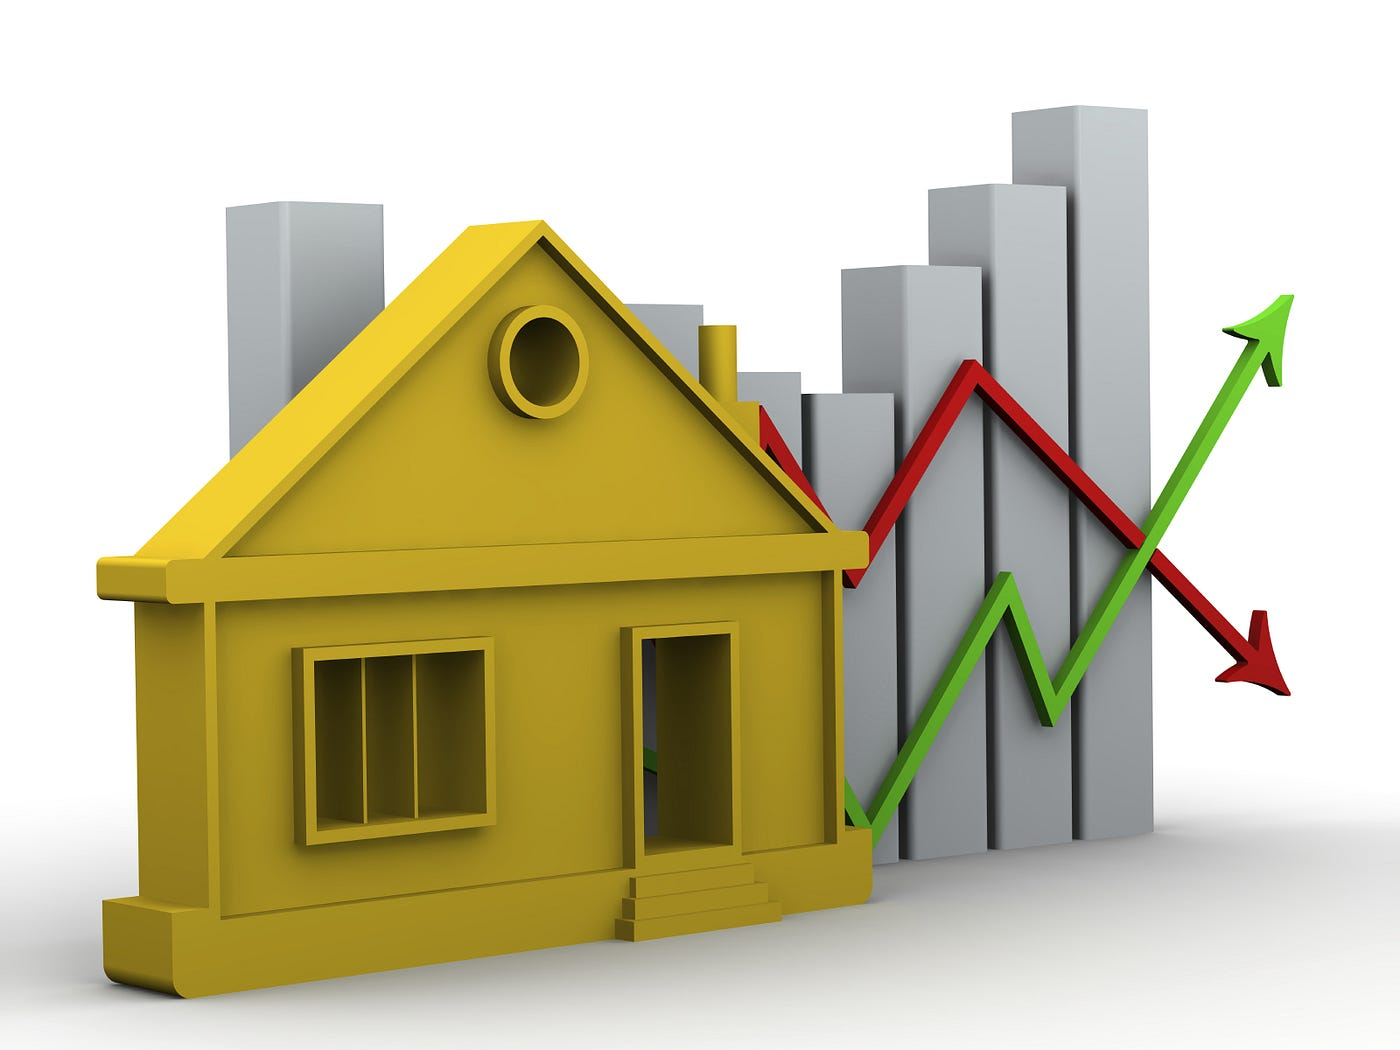

### Step 01. Load Important Modules

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
import os
import time
import warnings
import pickle
warnings.filterwarnings('ignore')
print('All Module Loaded Successfully!!')

All Module Loaded Successfully!!


### Step 02. Data Load

In [2]:
data = fetch_california_housing()

In [3]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [8]:
df = pd.DataFrame(data.data, columns = data.feature_names)
df['MedHouseVal'] = data.target

In [6]:
data.target_names

['MedHouseVal']

In [9]:
df.sample(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
12729,5.0492,35.0,6.652542,1.031073,993.0,2.805085,38.61,-121.36,1.441
19837,2.2500,19.0,4.436709,1.025316,1327.0,4.199367,36.52,-119.28,0.532
17877,4.0655,33.0,4.809069,1.155131,1285.0,3.066826,37.40,-122.02,2.268
20106,3.0500,17.0,5.383764,1.095941,753.0,2.778598,37.94,-120.29,1.448
4849,1.2434,52.0,4.361905,1.050000,1186.0,2.823810,34.02,-118.31,0.984


In [10]:
print(data['DESCR'])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

### Step 03. Exploratory Data Analysis

In [11]:
rows, cols = df.shape
print('No of Rows:', rows)
print('No of Cols:', cols)

No of Rows: 20640
No of Cols: 9


In [12]:
df.sample(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
201,1.4886,50.0,4.025157,1.111111,1525.0,3.197065,37.78,-122.22,1.288
6494,4.2750,35.0,5.337176,1.031700,1414.0,4.074928,34.08,-118.01,1.736
10462,5.6754,12.0,5.380697,1.064343,1033.0,2.769437,33.48,-117.64,2.759
7243,1.9867,33.0,4.215517,1.030172,1472.0,3.172414,34.01,-118.12,1.663
20456,4.7574,10.0,4.978979,0.930931,1053.0,3.162162,34.27,-118.77,2.099


In [13]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [14]:
df.tail()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [15]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [16]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [17]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [18]:
len(df.columns)

9

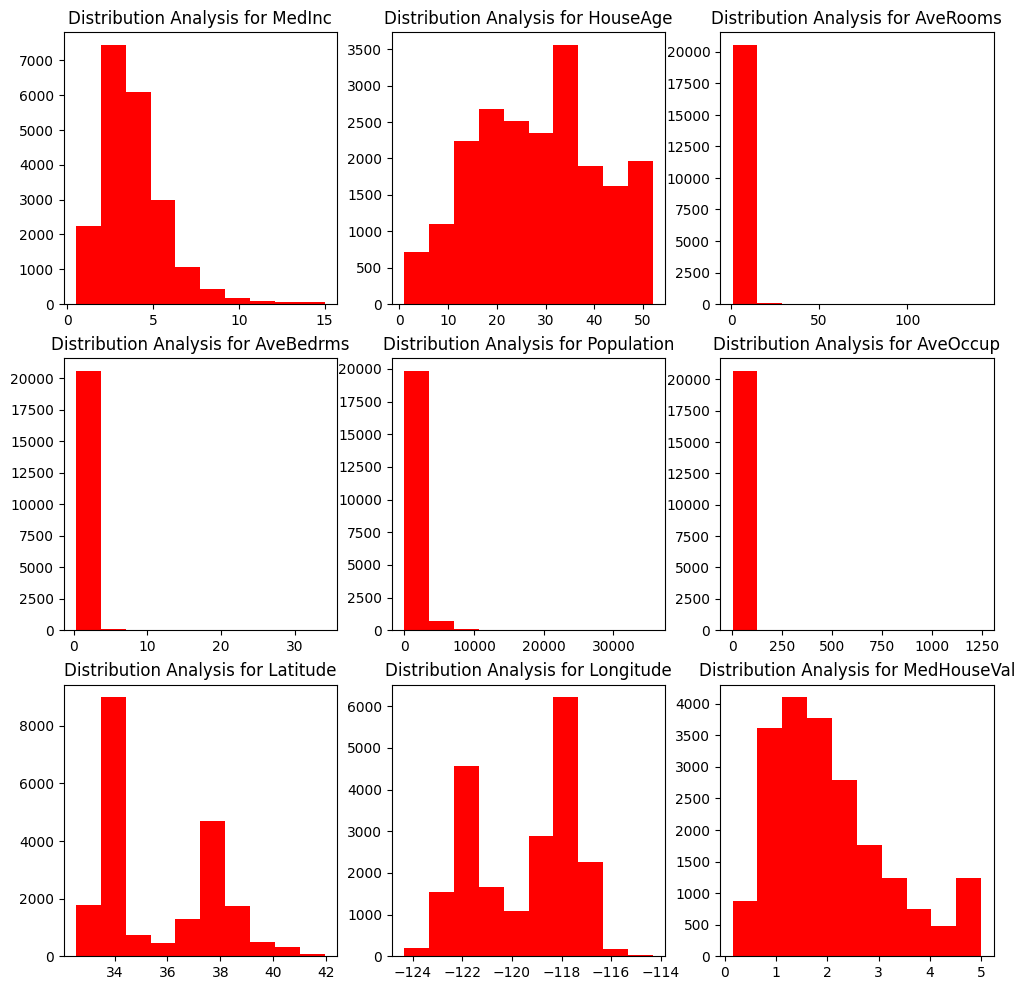

In [25]:
plt.figure(figsize=(12,12))
for i in range(len(df.columns)):
    plt.subplot(3,3, i+1)
    plt.title(f'Distribution Analysis for {df.columns[i]}')
    plt.hist(df[df.columns[i]], color = 'r')
plt.show()

<Axes: title={'center': 'Correlation b/w Features'}>

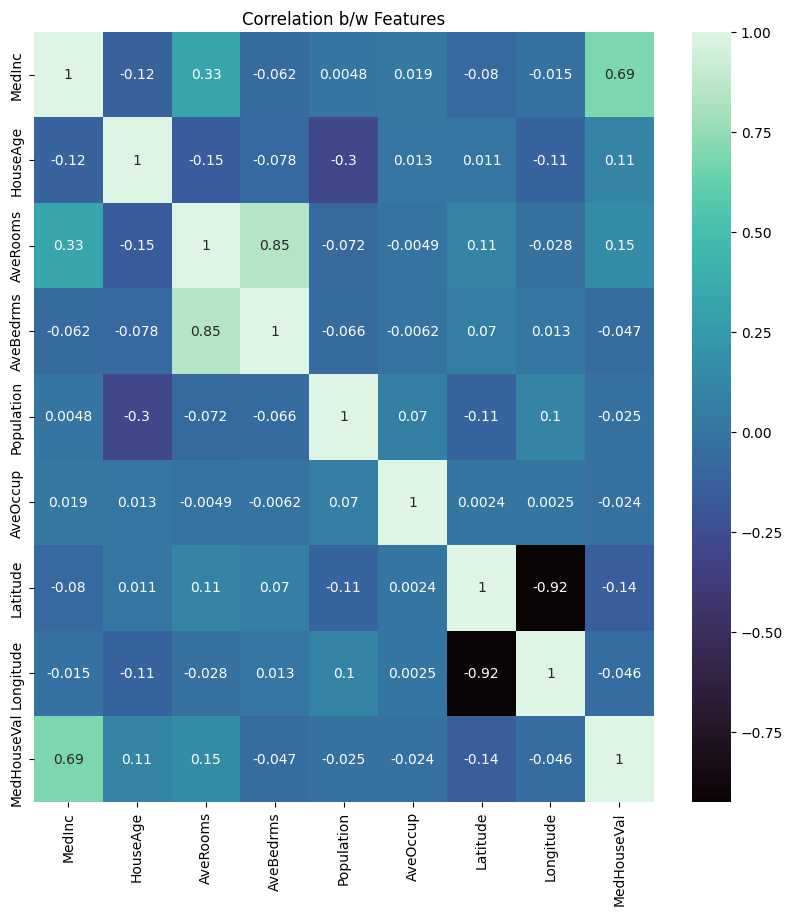

In [28]:
plt.figure(figsize=(10, 10))
plt.title('Correlation b/w Features')
sns.heatmap(df.corr(), annot = True, cmap = 'mako')

### Step 04. Data Preprocessing

In [31]:
X = df.iloc[:, :-2]
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85
...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43


In [32]:
y = df['MedHouseVal']
y

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

###### MIN_MAX_SCALER

In [33]:
scaler = MinMaxScaler()

In [35]:
scaled_X = scaler.fit_transform(X)

In [38]:
scaled_df = pd.DataFrame(scaled_X, columns = X.columns)

In [39]:
scaled_df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
0,0.539668,0.784314,0.043512,0.020469,0.008941,0.001499,0.567481
1,0.538027,0.392157,0.038224,0.018929,0.067210,0.001141,0.565356
2,0.466028,1.000000,0.052756,0.021940,0.013818,0.001698,0.564293
3,0.354699,1.000000,0.035241,0.021929,0.015555,0.001493,0.564293
4,0.230776,1.000000,0.038534,0.022166,0.015752,0.001198,0.564293
...,...,...,...,...,...,...,...
20635,0.073130,0.470588,0.029769,0.023715,0.023599,0.001503,0.737513
20636,0.141853,0.333333,0.037344,0.029124,0.009894,0.001956,0.738576
20637,0.082764,0.313725,0.030904,0.023323,0.028140,0.001314,0.732200
20638,0.094295,0.333333,0.031783,0.024859,0.020684,0.001152,0.732200


In [40]:
scaled_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,0.232464,0.541951,0.032488,0.022629,0.039869,0.001914,0.328572
std,0.131020,0.246776,0.017539,0.014049,0.031740,0.008358,0.226988
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.142308,0.333333,0.025482,0.019943,0.021974,0.001398,0.147715
50%,0.209301,0.549020,0.031071,0.021209,0.032596,0.001711,0.182784
75%,0.292641,0.705882,0.036907,0.022713,0.048264,0.002084,0.549416
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Step 05. Train & Test Part Data Devide

In [54]:
X_train, X_test, y_train, y_test = train_test_split(scaled_X, y, test_size = 0.2, random_state = 32)

In [55]:
X_train.shape

(16512, 7)

In [56]:
X_test.shape

(4128, 7)

In [57]:
y_train.shape

(16512,)

In [58]:
y_test.shape

(4128,)

### Step 06. Model Building ML

In [59]:
model = LinearRegression()

In [60]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 7.62, 0.84,-27.15,..., 0.73,-10.69, -0.3 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.1294
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](7,)","[31.85,29.19,16.51,..., 2.81, 0.55, 0.46]"


In [61]:
y_pred = model.predict(X_test)

In [62]:
compare_df = pd.DataFrame({'Actual Y': y_test, 'Predicted Y' : y_pred})

In [63]:
compare_df

,Actual Y,Predicted Y
20038,0.52300,0.834995
17684,0.87500,1.173940
9720,2.53800,2.009483
17295,5.00001,4.140879
18736,0.98100,1.535862
...,...,...
7573,1.18800,1.938689
11436,2.89800,2.774159
16564,3.27300,1.926759
5083,1.00000,1.292028


### Step 07. Model Evaluation

In [69]:
score = model.score(X_test, y_test)
print('Model Score: ',score)

Model Score:  0.5407455783669917


In [70]:
mae = mean_absolute_error(y_test, y_pred)
print('Mean Absolute Error: ', mae)

Mean Absolute Error:  0.5764152195596531


In [71]:
mse = mean_squared_error(y_test, y_pred)
print('Mean Squared Error: ', mse)

Mean Squared Error:  0.6279401775319309


In [72]:
rmse = root_mean_squared_error(y_test, y_pred)
print('Root Mean Squared Error: ', rmse)

Root Mean Squared Error:  0.7924267647750995


### Step 08. Final Model Checking

In [77]:
matrix_dict = {'Model Number':[], 'Model':[], 'Model Score':[], 'MAE':[], 'MSE':[], 'RMSE':[]}


for i in range(5000):
    X_train, X_test, y_train, y_test = train_test_split(scaled_X, y, test_size = 0.2, random_state = i)
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score = model.score(X_test, y_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    
    matrix_dict['Model Number'].append(i)
    matrix_dict['Model'].append(model)
    matrix_dict['Model Score'].append(score)
    matrix_dict['MAE'].append(mae)
    matrix_dict['MSE'].append(mse)
    matrix_dict['RMSE'].append(rmse)
    print(f'Checking Model {i+1}')
    display(clear = True)

matrix_df = pd.DataFrame(matrix_dict)
print('Done')

Done


In [78]:
matrix_df

,Model Number,Model,Model Score,MAE,MSE,RMSE
0,0,LinearRegression(),0.527683,0.579466,0.615881,0.784781
1,1,LinearRegression(),0.537468,0.570721,0.606699,0.778909
2,2,LinearRegression(),0.520340,0.579716,0.646114,0.803812
3,3,LinearRegression(),0.532628,0.572254,0.618151,0.786226
4,4,LinearRegression(),0.526180,0.571381,0.616356,0.785084
...,...,...,...,...,...,...
4995,4995,LinearRegression(),0.524110,0.581537,0.639002,0.799376
4996,4996,LinearRegression(),0.505095,0.584316,0.682270,0.825997
4997,4997,LinearRegression(),0.507829,0.581188,0.648234,0.805130
4998,4998,LinearRegression(),0.540960,0.567692,0.593010,0.770071


In [79]:
matrix_df['Model Score'].max()

0.5873209371614159

In [88]:
matrix_df['Model Score'].min()

-10.369343387087671

In [82]:
final_model_df = matrix_df[matrix_df['Model Score'] == matrix_df['Model Score'].max()]
final_model_df

,Model Number,Model,Model Score,MAE,MSE,RMSE
987,987,LinearRegression(),0.587321,0.558152,0.571567,0.75602


In [89]:
matrix_positive_df = matrix_df[matrix_df['Model Score'] >= 0.50]

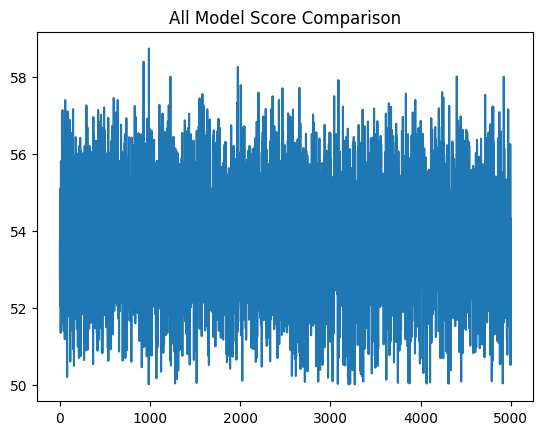

In [91]:
plt.plot(matrix_positive_df['Model Number'], matrix_positive_df['Model Score']*100)
plt.title('All Model Score Comparison') 
plt.show()

### Step 09. Final Model Save

In [93]:
final_model = final_model_df['Model']

In [95]:
final_model.values[0]

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 7.56, 0.85,-26.57,..., 0.69, -5.54, -0.28]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.1005
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](7,)","[31.81,29.18,16.47,..., 2.76, 1.19, 0.54]"


In [96]:
with open('chatgpt_for_house.pkl', 'wb') as f:
    pickle.dump(final_model.values[0], f)
print('Model Saved Successfully!!!')

Model Saved Successfully!!!


### Step 10. Model Deployment on Website

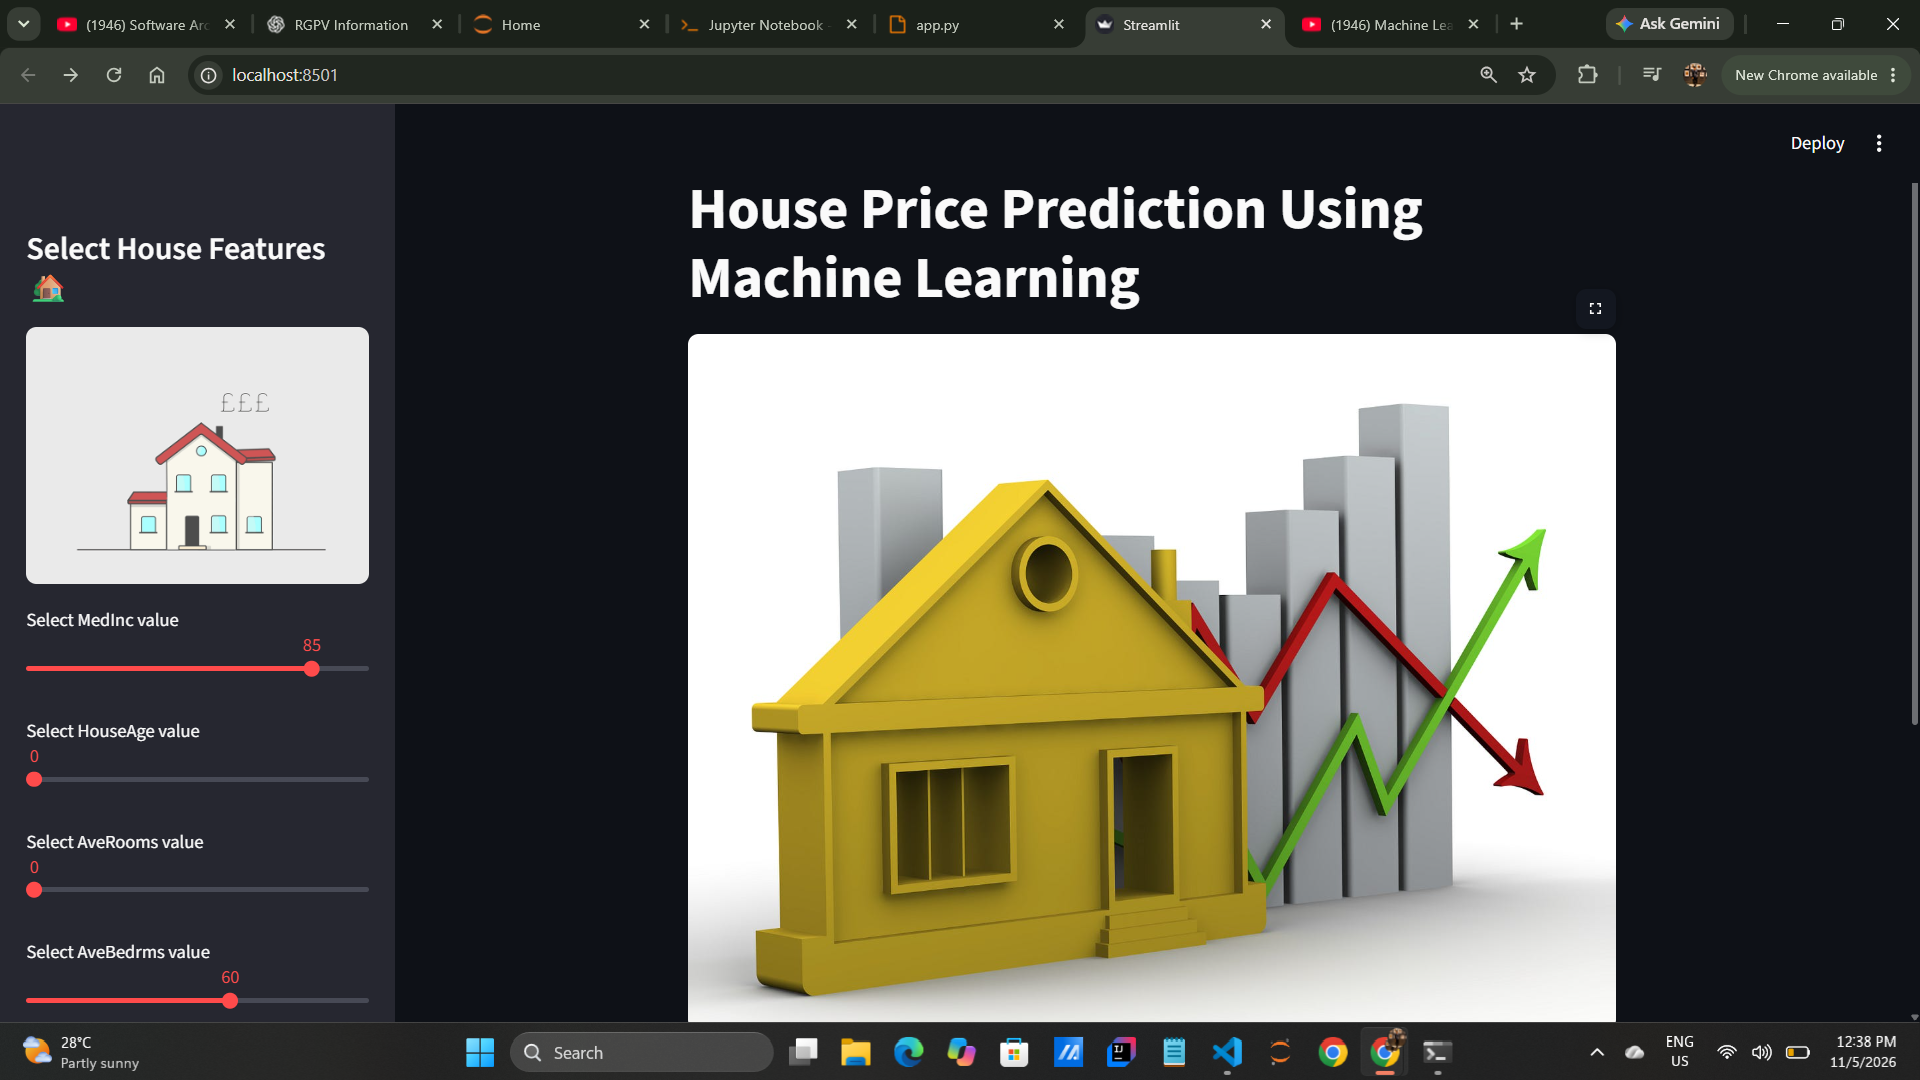